# Combine the two corridor result sets

The Cuebiq extraction was run twice, once per set of corridors (see
`east_bay_corridor_activity_full.ipynb` and `east_bay_corridor_activity_full2.ipynb`). Both runs export the
same set of gzipped CSV tables. This notebook stacks them into one consistent set of tables that every later
notebook reads, so nothing downstream has to know there were two runs.

| Set | Corridors | Source folder |
|---|---|---|
| 1 | 11 Oakland BIDs (`Oakland BID:1` ... `Oakland BID:11`) | `data/activity/east_bay_essential_results/` |
| 2 | 10 additional corridors (`c2_*`) | `data/activity/east_bay_essential_results2/` |

What this notebook does:

1. Loads every table from both sets and tags each row with `corridor_set` and a stable `corridor_slug`
   (the id used in file names on the front end).
2. Checks that the two runs are compatible (same provider schedule, same sample denominators, same period
   definitions, no duplicate rows).
3. Drops run-metadata columns that nothing downstream uses, and writes the stacked tables to
   `data/activity/processed/`.

**Things worth knowing about this data** (from the extraction notebooks' methods contract):

- Five *overlapping* time periods: `all`, `weekdays`, `weekends`, `nine-five` (weekdays 9:00-16:59) and `evening`
  (every day 17:00-22:59). They must never be summed together.
- Providers change at half-year boundaries (three **segments**: S1 2019-2022, S2 Jan-Jun 2023, S3 Jul 2023-2025).
  **Segments are not calibrated to each other**, so adjusted levels can be compared across corridors within a
  month, but not joined into a seamless trend across a segment break.
- *Adjusted* values only include devices with a matched Bay Area home, re-weighted by a monthly home sample
  index. *Raw* values include everyone.
- Corridors can share geohash cells, so corridor totals can't be summed into distinct East Bay visitors.

---

| | |
|---|---|
| **Inputs** | `data/activity/east_bay_essential_results/`, `data/activity/east_bay_essential_results2/` |
| **Outputs** | `data/activity/processed/*.csv.gz` and `corridor_lookup.csv` (git-ignored intermediates) |
| **Run after** | Nothing. This is the first notebook. |

In [1]:
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", message="Unable to import Axes3D")

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# --- Paths ---
# Repo root = nearest parent folder containing package.json, so this notebook runs from any depth.
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "package.json").exists())
DATA = ROOT / "data"                 # raw + intermediate files
SRC_DATA = ROOT / "src" / "data"     # final outputs consumed directly by the web app
ACTIVITY_DIR = DATA / "activity"
PROCESSED_DIR = ACTIVITY_DIR / "processed"

RESULT_SETS = {
    1: ACTIVITY_DIR / "east_bay_essential_results",
    2: ACTIVITY_DIR / "east_bay_essential_results2",
}

# --- Tables ---
# one gz file per month (YYYYMM.csv.gz)
MONTHLY_TABLES = ["corridor_stops", "corridor_origin_categories_monthly", "corridor_home_distance_monthly"]
# one gz file per half-year (YYYYH1.csv.gz)
HALF_YEAR_TABLES = ["corridor_homes", "corridor_repeat_visitors"]
# a single file, identical grain in both sets
SINGLE_TABLES = ["corridor_geography", "home_geography", "home_month_qa", "provider_schedule", "bay_month_denoms"]

# corridor_homes_monthly (~4M rows, 200MB) is deliberately NOT combined: the half-year corridor_homes table
# carries the same home-block-group information at a size the front-end pipeline can use.

# Columns each stacked table keeps (everything else is run metadata: provider ids, reference_* ...)
KEEP_COLUMNS = {
    "corridor_stops": [
        "year_month", "time_period", "raw_stop_count", "visit_count", "unique_devices",
        "home_matched_devices", "home_match_rate", "weight_eligible_devices",
        "adjusted_known_home_raw_stops", "adjusted_known_home_visits", "adjusted_known_home_unique_devices",
        "provider_segment",
    ],
    "corridor_origin_categories_monthly": [
        "year_month", "time_period", "home_geography", "raw_stop_count", "visit_count", "unique_devices",
        "normalized_raw_stop_count", "normalized_visit_count", "normalized_unique_devices", "provider_segment",
    ],
    "corridor_home_distance_monthly": [
        "year_month", "time_period", "distance_band", "raw_stop_count", "visit_count", "unique_devices",
        "normalized_raw_stop_count", "normalized_visit_count", "normalized_unique_devices", "provider_segment",
    ],
    "corridor_homes": [
        "half_year", "time_period", "block_group_id", "home_geography", "raw_stop_count", "visit_count",
        "unique_devices_within_half_year", "unique_device_months", "normalized_raw_stop_count",
        "normalized_visit_count", "normalized_unique_device_months", "provider_segment",
    ],
    "corridor_repeat_visitors": [
        "half_year", "time_period", "raw_stop_count", "visit_count", "unique_devices", "repeat_devices",
        "repeat_device_prop", "devices_active_multiple_months", "provider_segment",
    ],
}

TIME_PERIODS = ["all", "evening", "nine-five", "weekdays", "weekends"]
EXPECTED_MONTHS = 84   # Jan 2019 - Dec 2025
EXPECTED_HALF_YEARS = 14

# --- Chart styling (see dataviz skill: fixed categorical order, single-hue sequential) ---
CATEGORICAL_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
CHART_GRID_COLOR = "#e1e0d9"
CHART_MUTED_TEXT = "#898781"

In [3]:
def style_axis(ax, grid_axis="y"):
    """Shared cosmetic cleanup: recessive grid, no top/right spines."""
    ax.grid(axis=grid_axis, color=CHART_GRID_COLOR, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(colors=CHART_MUTED_TEXT)


def slugify(name):
    """'Koreatown/Northgate' -> 'koreatown_northgate'; stable id used in front-end file names."""
    name = name.replace("&", "and").replace("\xa0", " ").strip().lower()
    return re.sub(r"[^a-z0-9]+", "_", name).strip("_")

## Corridor lookup

`corridor_geography` lists every corridor in a run with its centroid (used later for travel distances).
Note that the corridor ids differ between runs (`Oakland BID:3` vs `c2_old_oakland`), and one corridor name
(`Dimond`) carries a trailing non-breaking space in the map's GeoJSON. Everything downstream joins on
`corridor_slug`, built here from the cleaned name.

In [4]:
lookup_parts = []
for set_id, folder in RESULT_SETS.items():
    geo = pd.read_csv(folder / "corridor_geography" / "corridor_geography.csv.gz")
    geo["corridor_set"] = set_id
    lookup_parts.append(geo)

lookup = pd.concat(lookup_parts, ignore_index=True)
lookup["corridor_name"] = lookup["corridor_name"].str.replace("\xa0", " ").str.strip()
lookup["corridor_slug"] = lookup["corridor_name"].map(slugify)
lookup = lookup.rename(columns={"corridor_lat": "lat", "corridor_lon": "lon"})
lookup = lookup[["corridor_slug", "corridor_id", "corridor_name", "corridor_set", "lat", "lon"]]

assert lookup.corridor_slug.is_unique, "slug collision"
assert lookup.corridor_id.is_unique, "corridor_id collision between sets"
print(f"{len(lookup)} corridors")
lookup

21 corridors


,corridor_slug,corridor_id,corridor_name,corridor_set,lat,lon
0,downtown,Oakland BID:1,Downtown,1,37.803623,-122.271957
1,chinatown,Oakland BID:2,Chinatown,1,37.799125,-122.267131
2,lake_merritt,Oakland BID:3,Lake Merritt,1,37.810102,-122.265853
3,koreatown_northgate,Oakland BID:4,Koreatown/Northgate,1,37.814743,-122.268580
4,montclair,Oakland BID:5,Montclair,1,37.827025,-122.209869
5,rockridge,Oakland BID:6,Rockridge,1,37.843274,-122.251875
6,temescal_telegraph,Oakland BID:7,Temescal/Telegraph,1,37.836390,-122.262765
7,fruitvale,Oakland BID:8,Fruitvale,1,37.778435,-122.221424
8,lakeshore,Oakland BID:9,Lakeshore,1,37.810710,-122.244471
9,jack_london,Oakland BID:10,Jack London,1,37.795545,-122.273917


In [5]:
# id -> slug, used to tag every table row below
ID_TO_SLUG = lookup.set_index("corridor_id")["corridor_slug"].to_dict()
ID_TO_SET = lookup.set_index("corridor_id")["corridor_set"].to_dict()

## Stack the per-period tables

Each table is read file by file (84 monthly or 14 half-yearly files per set), tagged with the corridor slug and
set, trimmed to the columns we use, and concatenated.

In [6]:
def read_partitions(set_id, table):
    folder = RESULT_SETS[set_id] / table
    files = sorted(folder.glob("*.csv.gz"))
    frames = [pd.read_csv(f, dtype={"block_group_id": str}) for f in files]
    return pd.concat(frames, ignore_index=True), len(files)


stacked = {}
partition_counts = []
for table in tqdm(MONTHLY_TABLES + HALF_YEAR_TABLES, desc="stacking tables"):
    parts = []
    for set_id in RESULT_SETS:
        df, n_files = read_partitions(set_id, table)
        df["corridor_slug"] = df["corridor_id"].map(ID_TO_SLUG)
        df["corridor_set"] = set_id
        parts.append(df)
        partition_counts.append({"table": table, "corridor_set": set_id, "files": n_files, "rows": len(df)})
    out = pd.concat(parts, ignore_index=True)
    assert out.corridor_slug.notna().all(), f"{table}: unmapped corridor ids"
    stacked[table] = out[["corridor_slug", "corridor_set"] + KEEP_COLUMNS[table]]

pd.DataFrame(partition_counts).pivot(index="table", columns="corridor_set", values=["files", "rows"])

stacking tables:   0%|          | 0/5 [00:00<?, ?it/s]

files         rows         
corridor_set                           1   2        1        2
table                                                         
corridor_home_distance_monthly        84  84    35028    31377
corridor_homes                        14  14  1416575  1010006
corridor_origin_categories_monthly    84  84    23029    20818
corridor_repeat_visitors              14  14      770      700
corridor_stops                        84  84     4620     4200

## Single-file tables

`provider_schedule` and `bay_month_denoms` describe the Bay-wide home sample, which is not corridor-specific,
so the two runs should be identical. If they are, one copy is kept. `home_month_qa` sums over each run's own
corridors, so both copies are kept (tagged by set). `home_geography` is the union of block groups seen by
either run.

In [7]:
single = {}
for table in SINGLE_TABLES:
    if table == "corridor_geography":
        continue
    per_set = {
        s: pd.read_csv(folder / table / f"{table}.csv.gz", dtype={"geoid": str}) for s, folder in RESULT_SETS.items()
    }
    if table in ("provider_schedule", "bay_month_denoms"):
        a, b = per_set[1].sort_values("year_month").reset_index(drop=True), per_set[2].sort_values("year_month").reset_index(drop=True)
        same = a.equals(b)
        # NaN-safe numeric comparison for bay_month_denoms
        if not same:
            num = a.select_dtypes("number").columns
            same = np.allclose(a[num].fillna(-1), b[num].fillna(-1)) and a.drop(columns=num).equals(b.drop(columns=num))
        print(f"{table}: identical across sets -> {same}")
        assert same
        single[table] = a
    elif table == "home_geography":
        union = pd.concat(per_set.values(), ignore_index=True).drop_duplicates()
        union["geoid"] = union["geoid"].str.zfill(12)
        dupe_ids = union.block_group_id.duplicated().sum()
        print(f"home_geography: {len(union)} unique block groups, {dupe_ids} conflicting duplicates")
        assert dupe_ids == 0
        single[table] = union
    else:  # home_month_qa
        single[table] = pd.concat([d.assign(corridor_set=s) for s, d in per_set.items()], ignore_index=True)

single["provider_schedule"].groupby(["provider_segment", "provider_id"]).year_month.agg(["min", "max", "count"])

home_geography: 4753 unique block groups, 0 conflicting duplicates
provider_schedule: identical across sets -> True
bay_month_denoms: identical across sets -> True


,,min,max,count
provider_segment,provider_id,,,
S1_LIMA,LIMA,201901,202212,48
S2_SIERRA,SIERRA,202301,202306,6
S3_PAPA,PAPA,202307,202512,30


## Integrity checks

- every corridor has all 84 months (monthly tables) / 14 half-years (half-year tables)
- the five time periods are present
- no duplicate keys

In [8]:
checks = []

stops = stacked["corridor_stops"]
n_months = stops.groupby(["corridor_slug", "time_period"]).year_month.nunique().unstack("time_period")
checks.append(("corridor_stops months/corridor/period", n_months.min().min(), n_months.max().max()))
print("Months per corridor x period in corridor_stops (expected 84):")
display(n_months.T.describe().loc[["min", "max"]].T.query("min != 84 or max != 84"))

repeat = stacked["corridor_repeat_visitors"]
n_hy = repeat.groupby(["corridor_slug", "time_period"]).half_year.nunique()
print(f"\nHalf-years per corridor x period in repeat table: min {n_hy.min()}, max {n_hy.max()} (expected {EXPECTED_HALF_YEARS})")

for table, keys in {
    "corridor_stops": ["corridor_slug", "year_month", "time_period"],
    "corridor_repeat_visitors": ["corridor_slug", "half_year", "time_period"],
    "corridor_homes": ["corridor_slug", "half_year", "time_period", "block_group_id"],
    "corridor_origin_categories_monthly": ["corridor_slug", "year_month", "time_period", "home_geography"],
    "corridor_home_distance_monthly": ["corridor_slug", "year_month", "time_period", "distance_band"],
}.items():
    n_dupes = stacked[table].duplicated(keys).sum()
    print(f"{table:40s} duplicate keys: {n_dupes}")
    assert n_dupes == 0

assert set(stops.time_period.unique()) == set(TIME_PERIODS)

Months per corridor x period in corridor_stops (expected 84):


,min,max
corridor_slug,,



Half-years per corridor x period in repeat table: min 14, max 14 (expected 14)
corridor_stops                           duplicate keys: 0
corridor_repeat_visitors                 duplicate keys: 0


corridor_homes                           duplicate keys: 0
corridor_origin_categories_monthly       duplicate keys: 0
corridor_home_distance_monthly           duplicate keys: 0


### Missing months

If a corridor-period has no row for a month (e.g. nobody visited in the evening), later notebooks treat it as
a gap rather than a zero. This table counts those gaps so we know whether it matters.

In [9]:
all_months = sorted(single["provider_schedule"].year_month.unique())
full_index = pd.MultiIndex.from_product(
    [lookup.corridor_slug, TIME_PERIODS, all_months], names=["corridor_slug", "time_period", "year_month"]
)
present = stops.set_index(["corridor_slug", "time_period", "year_month"]).index
missing = full_index.difference(present)
print(f"{len(missing)} missing corridor x period x month rows out of {len(full_index)}")
if len(missing):
    miss_df = missing.to_frame(index=False)
    display(miss_df.groupby(["corridor_slug", "time_period"]).size().rename("missing_months").sort_values(ascending=False).head(15))

0 missing corridor x period x month rows out of 8820


## Sanity charts

Two things to look at before trusting any downstream number:

1. How many corridor-months are there per segment? (Confirms the provider schedule.)
2. How does the Bay home-match rate behave over time? A low match rate means fewer devices feed the
   *adjusted* (known-home) numbers, so they are noisier.

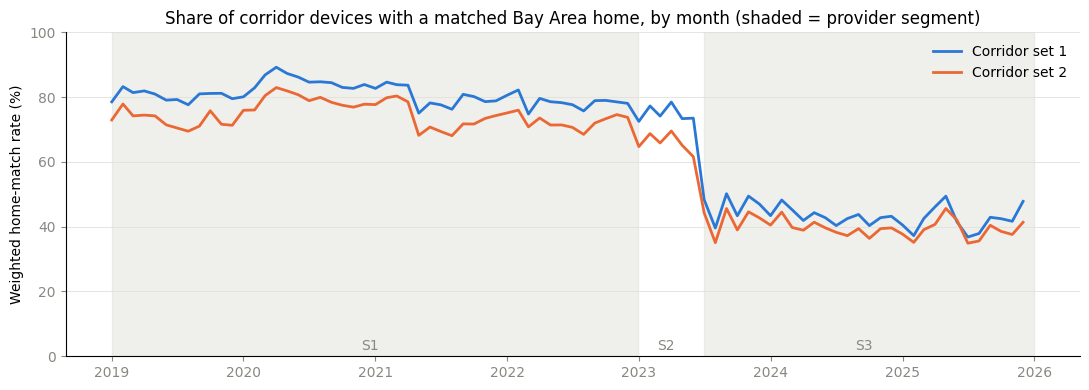

In [10]:
qa = single["home_month_qa"].copy()
qa["month"] = pd.to_datetime(qa.year_month.astype(str), format="%Y%m")
sched = single["provider_schedule"].assign(month=lambda d: pd.to_datetime(d.year_month.astype(str), format="%Y%m"))

fig, ax = plt.subplots(figsize=(11, 4))
for color, (set_id, grp) in zip(CATEGORICAL_PALETTE, qa.groupby("corridor_set")):
    grp = grp.sort_values("month")
    ax.plot(grp.month, grp.weighted_home_match_rate * 100, color=color, linewidth=2, label=f"Corridor set {set_id}")

segment_bounds = sched.groupby("provider_segment").month.agg(["min", "max"])
for i, (seg, row) in enumerate(segment_bounds.iterrows()):
    ax.axvspan(row["min"], row["max"] + pd.offsets.MonthEnd(0), color=CHART_GRID_COLOR, alpha=0.5 if i % 2 == 0 else 0.0, zorder=0)
    ax.text(row["min"] + (row["max"] - row["min"]) / 2, 2, seg.split("_")[0], ha="center", color=CHART_MUTED_TEXT)

ax.set_ylim(0, 100)
ax.set_ylabel("Weighted home-match rate (%)")
ax.set_title("Share of corridor devices with a matched Bay Area home, by month (shaded = provider segment)")
ax.legend(frameon=False, loc="upper right")
style_axis(ax)
plt.tight_layout()
plt.show()

The match rate falls sharply in the later (S3) provider segment: fewer devices have a usable Bay home there,
so *adjusted* (known-home) estimates are noisier after mid-2023. This is the main reason origin shares in
later notebooks pool across the full period rather than looking at single months.

## Write the stacked tables

CSV (gzip) keeps the intermediates portable. `block_group_id` and `geoid` are written as strings so the
leading zero of the 12-digit GEOID survives the round trip.

In [11]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

outputs = {**stacked, **single}
outputs["corridor_lookup"] = lookup

written = []
for name, df in tqdm(outputs.items(), desc="writing"):
    path = PROCESSED_DIR / (f"{name}.csv" if name == "corridor_lookup" else f"{name}.csv.gz")
    df.to_csv(path, index=False)
    written.append({"file": path.name, "rows": len(df), "MB": round(path.stat().st_size / 1e6, 2)})

pd.DataFrame(written)

writing:   0%|          | 0/10 [00:00<?, ?it/s]

,file,rows,MB
0,corridor_stops.csv.gz,8820,0.41
1,corridor_origin_categories_monthly.csv.gz,43847,1.36
2,corridor_home_distance_monthly.csv.gz,66405,2.08
3,corridor_homes.csv.gz,2426581,57.13
4,corridor_repeat_visitors.csv.gz,1470,0.03
5,home_geography.csv.gz,4753,0.09
6,home_month_qa.csv.gz,168,0.00
7,provider_schedule.csv.gz,84,0.00
8,bay_month_denoms.csv.gz,84,0.00
9,corridor_lookup.csv,21,0.00
